# Logistic Regression on the Titanic Dataset (Contains Intentional Errors)

This notebook demonstrates a logistic regression workflow using Seaborn's Titanic dataset. Several intentional mistakes have been included for instructional purposes. 

Please review the analysis, identify the errors, and propose corrections.

See https://www.interactive-ml.com/logistic-regression.html for a review of logistic regression.

Full disclosure: This was initially generated by AI and but then heavily edited.

## 1. Import Libraries

We import the libraries needed for data preparation, visualization, model building, and evaluation.

In [3]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score

## 2. Load and Prepare Data

The Titanic dataset contains information about passengers aboard the Titanic. The target variable is `survived`, indicating whether a passenger survived (1) or did not survive (0).

For simplicity, only a few predictor variables are used.

In [35]:
titanic = sns.load_dataset('titanic')

df = titanic[['survived','pclass','fare','age']].dropna()

df.head()

,survived,pclass,fare,age
0,0,3,7.2500,22.0
1,1,1,71.2833,38.0
2,1,3,7.9250,26.0
3,1,1,53.1000,35.0
4,0,3,8.0500,35.0


In [6]:
df['survived'].value_counts()

survived
0    424
1    290
Name: count, dtype: int64

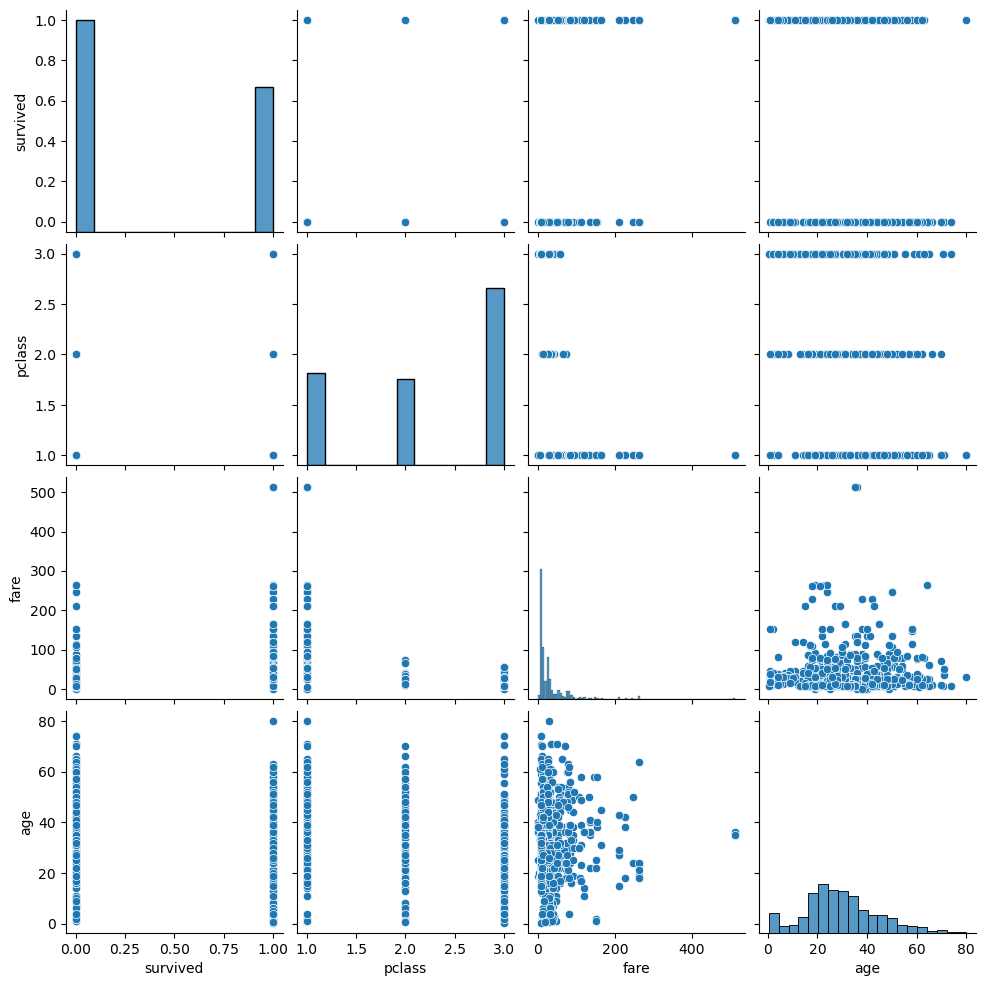

In [7]:
sns.pairplot(df)

## 3. Check Logistic Regression Assumptions

One assumption of logistic regression is that predictors should not exhibit excessive multicollinearity.

The code below examines pairwise correlations among predictors.

<Axes: >

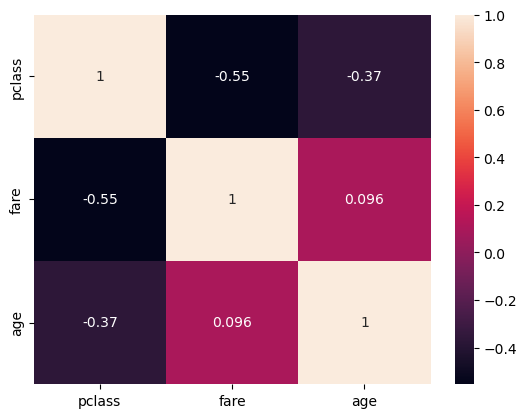

In [37]:
# INTENTIONAL ERROR -- took survived out
sns.heatmap(df[['pclass','fare','age']].corr(), annot=True)

Because variables do not show noticeable correlations, we can conclude that multicollinearity is not present and the assumption is fully satisfied. 


## 4. Check Linearity of Continuous Predictors with the Logit
There must be a linear relationship between continuous independent variables and the log-odds (logit) of the dependent variable 

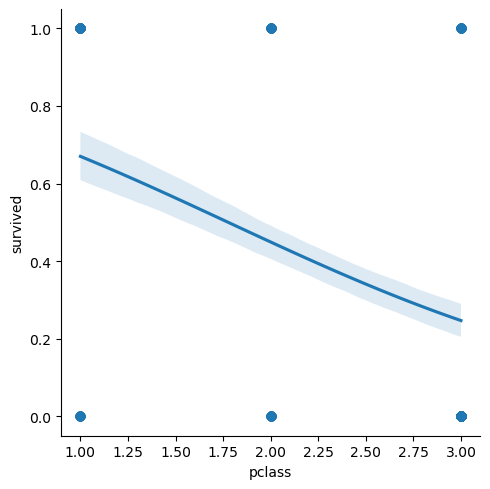

In [12]:
sns.lmplot(
    x="pclass",
    y="survived",
    data=df,
    logistic=True
)

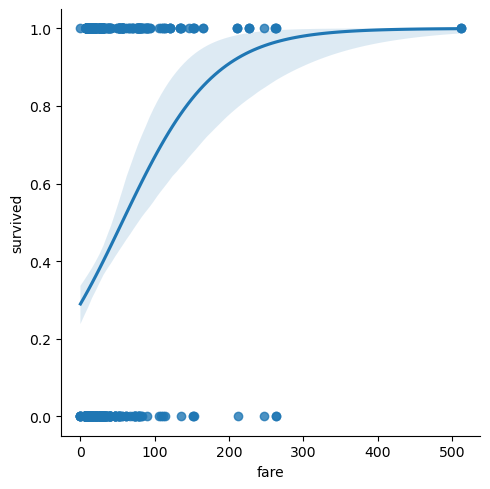

In [13]:
sns.lmplot(
    x="fare",
    y="survived",
    data=df,
    logistic=True
)

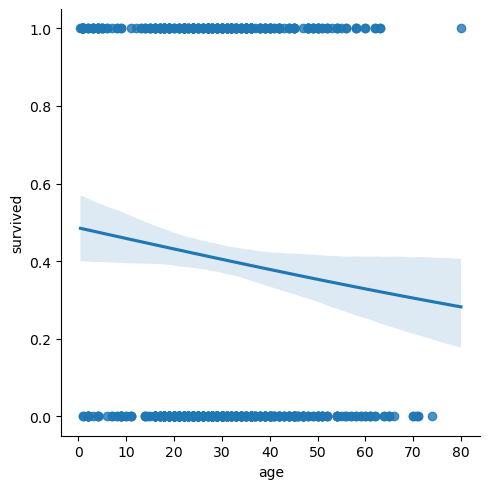

In [14]:
sns.lmplot(
    x="age",
    y="survived",
    data=df,
    logistic=True
)

When viewing a logistic regplot, look for a smooth, steadily increasing or decreasing relationship. If the curve shows unusual bends, plateaus, or changes in direction, that may indicate the predictor is not adequately modeled. However, the regplot is only a screening tool. A Box-Tidwell test or a plot of the predictor against the logit provides a more direct assessment of the linearity-of-the-logit assumption.

There is a problem with fare.  Since this is pretty skewed, the following will address this:

In [17]:
df["log_fare"] = np.log1p(df["fare"])

Taking the logarithm of right-skewed (positively skewed) data is acceptable because the logarithmic function compresses large values and stretches small values. 

## 5. Split Data and Train Model

We separate predictors and target values, split the dataset into training and testing sets, and fit a logistic regression model.

In [20]:
X = df[['pclass','log_fare','age']]
y = df['survived']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

model = LogisticRegression(max_iter=1000)
model.fit(X_train,y_train)

y_pred = model.predict(X_test)

## 6. Evaluate the Model

A confusion matrix compares actual and predicted values. The matrix should be built using actual class labels first and predicted labels second.

In [40]:
# INTENTIONAL ERROR  -- now fixed... arguments were swapped
cm = confusion_matrix(y_test, y_pred)
print(cm)

acc = accuracy_score(y_test, y_pred)
print('Accuracy:', acc)

[[111  15]
 [ 47  42]]
Accuracy: 0.7116279069767442


### Model Interpretation 

The model accuracy demonstrates ??? predictive performance.